# LiveBench-format Evaluation Notebook
Evaluating LiveBench with original script needs efforts and expensive due to expensive gpt-o3 as LLM-judge.

This notebook is a complete interactive-readable script to help you evaluating LiveBench score easily.
We also modify the scoring process to use more cost-efficient llm-judge.

**Requirement:**
* Need OPENROUTER_API_KEY, please put API into `os.environ["OPEN_ROUTER_API_KEY"]`
* Input input filename in `INPUT_FILE_NAME_LIST`, and your file-type (either .csv or .jsonl) in `INPUT_FILE_TYPE`

In [ ]:
## RUN CONFIG

USE_API = True # for AMPS_Hard which need LLM to check solutions
DEBUG = True # for _score_worker

API_MODEL_NAME = "xiaomi/mimo-v2-flash" # or "openai/gpt-oss-120b", but see NOTE in is_equiv_llm below

BASE_URL = "https://openrouter.ai/api/v1" # for openrouter
MAX_TOKENS = 512 # 512-1024 Should be enough to check literal equivalent of AMPS_Hard

TIMEOUT_SECONDS = 15 
INPUT_FILE_TYPE = "csv" # or "jsonl" 
INPUT_FILE_NAME_LIST = [
                        "data/yourfile" # <-- either input your csv/jsonl full-path here, without .csv or .jsonl
                       ]


### Read input & Fix CSV string to List/Dict

In [ ]:
import pandas as pd

input_df_list = []

for name in INPUT_FILE_NAME_LIST:
    if INPUT_FILE_TYPE == 'csv':
        input_df_list.append(pd.read_csv(f"{name}.{INPUT_FILE_TYPE}"))
        
    elif INPUT_FILE_TYPE == 'jsonl':
        input_df_list.append(pd.read_json(f"{name}.{INPUT_FILE_TYPE}", orient='records', lines=True))

    else: # e.g. parquet
        raise ValueError(f"file type: {INPUT_FILE_TYPE} -- not supported")

input_df = pd.concat(input_df_list)

if INPUT_FILE_TYPE == 'csv':
    import ast
    input_df['choices'] = input_df['choices'].apply(ast.literal_eval)
    input_df['turns'] = input_df['turns'].apply(ast.literal_eval)

print(f'input_df shape is {input_df.shape}')
display(input_df.tail(3))
input_df.head(3)

input_df shape is (128, 17)


/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: invalid value encountered in greater
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in less
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in greater
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()


,question_id,turns,answer_id,ground_truth,model_id,choices,tstamp,category,task,subtask,total_output_tokens,livebench_release_date,public_test_cases,private_test_cases,original_json,partial_solution,full_response
125,f78df88e6755702752e1c216f9734cbf1803a006546503...,[### Instructions: You are an expert Python pr...,ed1f3753-5901-4123-bfe3-2aa0805e7177,NaN,openai/gpt-oss-20b,"[{'index': 0, 'turns': ['<think> We need to wr...",1.768661e+09,coding,LCB_generation,LCB_generation,345,2024-06-24,"[{""input"": ""1 2 3 4 5 6 7 8 9\n4 5 6 7 8 9 1 2...",eJzNVrtuFEEQJCDiK0YXW0jznuEjiEEsGRc4WVu6c2AhJP...,"{'question_title': 'Number Place', 'question_c...",NaN,ChatCompletion(id='gen-1768661326-c64B9pL34IG9...
126,fe6312c9e8cb798517e3695c245cbbfbf4fd6dc7379036...,[### Instructions: You are an expert Python pr...,c9343eb2-e870-4c57-88d6-dfce1e0ddecc,NaN,openai/gpt-oss-20b,"[{'index': 0, 'turns': ['<think> We need to fi...",1.768661e+09,coding,coding_completion,coding_completion,3906,2024-06-24,"[{""input"": ""[1, 5, 3, 9, 8]\n2"", ""output"": ""[1...",eJyU3d2qdEuWFmAPPPUeijoT6iAjxl+kVyK0Hoi00CDdgt...,{'question_title': 'make-lexicographically-sma...,class Solution(object):\n def lexicographic...,ChatCompletion(id='gen-1768661331-mmUAhHrIczem...
127,ffdb71c563e5f8e936ab2649a069bfbdbebcde991c6ae1...,[### Instructions: You are an expert Python pr...,2713c62e-a242-48c2-9132-c3d57dc2bb28,NaN,openai/gpt-oss-20b,"[{'index': 0, 'turns': ['<think> We need to de...",1.768661e+09,coding,LCB_generation,LCB_generation,1798,2024-07-26,"[{""input"": ""[8, 4, 2, 30, 15]"", ""output"": ""tru...",eJyll02KHEcQhb3wAXyEZtaNib/MjPRJDEILYSQQCElYPQ...,{'question_title': 'find-if-array-can-be-sorte...,NaN,ChatCompletion(id='gen-1768661362-qwQEXB4Y7BZb...


/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: invalid value encountered in greater
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in less
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in greater
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()


,question_id,turns,answer_id,ground_truth,model_id,choices,tstamp,category,task,subtask,total_output_tokens,livebench_release_date,public_test_cases,private_test_cases,original_json,partial_solution,full_response
0,009f4f7e8275c73de2eae601d76ff7163f613880788d87...,[### Instructions: You are an expert Python pr...,106423f6-e145-4fb9-90fd-c0b94a809701,NaN,openai/gpt-oss-20b,"[{'index': 0, 'turns': ['<think> We need to fi...",1.768660e+09,coding,coding_completion,coding_completion,14162,2024-06-24,"[{""input"": ""\""accca\""\n2"", ""output"": ""3"", ""tes...",eJyknMmuLstVhBnwINYdM3CDBeJJkPAk+75Z2WciJF6C9y...,{'question_title': 'maximize-the-number-of-par...,class Solution(object):\n def maxPartitions...,ChatCompletion(id='gen-1768659532-rdz1QG6qVc2Y...
1,0119bdbf9e79f05e988b6d3408e2fdc0b7e4bc11e81ff9...,[### Instructions: You are an expert Python pr...,3449aa44-7843-4c55-a485-b924ef8e3f96,NaN,openai/gpt-oss-20b,"[{'index': 0, 'turns': ['<think> We need to wr...",1.768660e+09,coding,coding_completion,coding_completion,427,2024-07-26,"[{""input"": ""[2, 11, 10, 1, 3]\n10"", ""output"": ...",eJztls1qFEEQxz148imGOS9SX10f4s2XEGIOIhECsglk9i...,{'question_title': 'minimum-operations-to-exce...,class Solution(object):\n def minOperations...,ChatCompletion(id='gen-1768659668-pmigy5a5Yguv...
2,01c73e7f5bd7b486915f97829994aca9b95d6116c510d9...,[### Instructions: You are an expert Python pr...,6bf700dd-f347-4df5-98b7-4e401bdf225b,NaN,openai/gpt-oss-20b,"[{'index': 0, 'turns': ['<think> We need to fi...",1.768660e+09,coding,LCB_generation,LCB_generation,285,2024-06-24,"[{""input"": ""[1, 2, 3, 4, 5]"", ""output"": ""7"", ""...",eJzlVE1LAzEQ9SDevPkDwp6DJJlsPvwlQulBpEJB2kK3Bx...,{'question_title': 'maximum-strong-pair-xor-i'...,NaN,ChatCompletion(id='gen-1768659670-jJzFO8pilpnv...


In [ ]:
from IPython.display import display, Markdown
display(Markdown(input_df.iloc[2]['choices'][0]['turns'][0]))

<think>
We need to find maximum XOR among pairs (x,y) from array that satisfy |x - y| <= min(x,y). We can brute force all pairs including same indices. nums length up to 50, so 2500 pairs - trivial.

So implement double loop including same elements. Condition: abs(x - y) <= min(x, y). Compute xor and track max. Return max.

Edge cases: no pairs? at least one element, so min >=1. At least one strong pair? For a single element, pair with itself satisfies |x-x|=0 <= min(x,x)=x. So we always have at least that pair.

Ok.

Implementation straightforward.

Time O(n^2). We'll import List.

Let's produce full code.
</think>
```python
from typing import List

class Solution:
    def maximumStrongPairXor(self, nums: List[int]) -> int:
        max_xor = 0
        n = len(nums)
        for i in range(n):
            for j in range(i, n):  # include same element and avoid duplicate computations
                x, y = nums[i], nums[j]
                if abs(x - y) <= min(x, y):
                    val = x ^ y
                    if val > max_xor:
                        max_xor = val
        return max_xor
```

## START from cloning LiveBench

In [7]:
!git clone https://github.com/LiveBench/LiveBench.git

Cloning into 'LiveBench'...
remote: Enumerating objects: 2820, done.
remote: Counting objects: 100% (783/783), done.
remote: Compressing objects: 100% (223/223), done.
remote: Total 2820 (delta 667), reused 582 (delta 559), pack-reused 2037 (from 2)
Receiving objects: 100% (2820/2820), 15.53 MiB | 19.69 MiB/s, done.
Resolving deltas: 100% (1579/1579), done.


In [8]:
import pandas as pd
import numpy as np

print(pd.__version__)
print(np.__version__)

%cd LiveBench

2.2.3
1.26.4
/kaggle/working/LiveBench


In [ ]:
## NOTE: if there is some problem to script below, you need to try these 3 lines below (this is needed for Kaggle)
# import pyarrow
# current_version = pyarrow.__version__
# !pip install --quiet -e . "pyarrow=={current_version}"

## We are now initializing LiveBench evaluator

In [10]:
import sympy
import tiktoken
from tqdm import tqdm
tqdm.pandas()

enc = tiktoken.get_encoding("cl100k_base")
sympy.sqrt(3)

sqrt(3)

In [11]:
from livebench.process_results.math.math_competitions.utils import (
    mathcontest_process_results, 
    aime_process_results
)
# from livebench.process_results.math.AMPS_Hard.utils import amps_hard_process_results # we write our own version below to use our own LLM API
from livebench.process_results.math.olympiad.utils import proof_rearrangement_process_results
from livebench.process_results.reasoning.web_of_lies_v2.utils import web_of_lies_process_results
from livebench.process_results.reasoning.web_of_lies_v3.utils import web_of_lies_v3_process_results
from livebench.process_results.reasoning.house_traversal.utils import house_traversal_process_results
from livebench.process_results.reasoning.zebra_puzzle.utils import get_zebra_puzzle_evaluator
from livebench.process_results.reasoning.spatial.utils import spatial_process_results
from livebench.process_results.reasoning.theory_of_mind.utils import theory_of_mind_process_results
from livebench.process_results.coding.utils import LCB_generation_process_results, code_generation_process_results
from livebench.process_results.instruction_following.utils import instruction_following_process_results, ifbench_process_results

from livebench.process_results.writing.plot_unscrambling.utils import plot_unscrambling_process_results
from livebench.process_results.writing.typos.utils import typos_process_results
from livebench.process_results.writing.connections.utils import get_connections_puzzle_evaluator

### AMPS needs LLM-API (by default, it will call expensive gpt-o3, so we use the cheaper one here)

In [12]:
from livebench.process_results.util import last_boxed_only_string, remove_boxed
from livebench.process_results.math.AMPS_Hard.utils import normalize_final_answer, parse, is_equiv

In [13]:
from typing import List, Dict, Any, Optional, Union, Tuple

class LiveBenchModel:
    """Base class to standardize generation across Local and API models."""
    def generate(self, messages: List[Dict[str, str]], temperature: float, max_tokens: int) -> Tuple[str, int]:
        raise NotImplementedError

class OpenAIAPIModel(LiveBenchModel):
    """Wrapper for OpenAI-compatible APIs."""
    def __init__(self, api_key: str, model_name: str,
                 base_url: str = None,
                 extra_body: str = {} # extra_body can either be here or in generate()
                ):
        try:
            from openai import OpenAI
        except ImportError:
            raise ImportError("Please install openai: pip install openai")
        
        self.client = OpenAI(api_key=api_key, base_url=base_url)
        self.model_name = model_name
        self.extra_body = extra_body

    def generate(self, messages: List[Dict[str, str]], 
                 temperature: float, 
                 max_tokens: int,
                 ) -> Tuple[str, int]:
        response = self.client.chat.completions.create(
            model=self.model_name,
            messages=messages,
            temperature=temperature,
            max_tokens=max_tokens,
            extra_body=self.extra_body
        )
        
        content = response.choices[0].message.content
        # Extract usage stats if available
        usage = getattr(response, 'usage', None)
        total_tokens = usage.completion_tokens if usage else 0

        return content, total_tokens, response

In [ ]:
if USE_API:
    print('use API')
    os.environ["OPEN_ROUTER_API_KEY"] = api_key # this will flag the evaluator to score with LLM

    extra_body = {}
    if MAX_TOKENS > 0:
        extra_body = {
                "include_reasoning": True 
            }
    try:
        runner_model = OpenAIAPIModel(api_key=api_key, model_name=API_MODEL_NAME, base_url=BASE_URL, extra_body=extra_body)
        print(f'init {API_MODEL_NAME} success!!')
    except Exception as e:
        raise Exception(f"API Could not be loaded : {e}")
else:
    print('not use API')

    

use API
init xiaomi/mimo-v2-flash:free success!!


In [ ]:
def is_equiv_llm(x1: str, x2: str, debug=False) -> bool:
    """
    x1 and x2 are normalized latex string
    """

    prompt = f'''Are these latex expressions equivalent or negatives of each other. 
    Reply "yes" or "no" at the end: \n "{x1}" and "{x2} \n (You can include your thought in <think> ... </think>)'''
    messages = [{"role": "user", "content": prompt}]
    output_text, total_tokens, response = runner_model.generate(messages, temperature=0.5, max_tokens=MAX_TOKENS)    
    
    if debug:
        """
        NOTE
        "openai/gpt-oss-120b:free" : reasoning is in response.choices[0].message.reasoning, separated from content
        "xiaomi/mimo-v2-flash:free" : reasoning is embeded in response.choices[0].message.content, (response.choices[0].message.reasoning is None)
        """
        print(f"LLM: total_tokens:{total_tokens}\n response.choices[0].message:{response.choices[0].message}")
    
    if "yes" in output_text[-10:].lower() and not "no" in output_text[-10:].lower():
        return True

    return False
    

In [16]:
def amps_hard_process_results(ground_truth: str, llm_answer: str, debug=False, skip_sympy=False) -> int:
    retval = 0
    parsed_answer = None

    if isinstance(ground_truth, list):
        ground_truth = ground_truth[-1]
    llm_answer = llm_answer.replace("+C","")
    llm_answer = llm_answer.replace("+ C", "")
    llm_answer = llm_answer.replace("+ c", "")
    llm_answer = llm_answer.replace("+c", "")
    llm_answer = llm_answer.replace("\\\\fbox{", "\\\\boxed{")
    llm_answer = llm_answer.replace("\\dfrac", "\\frac")
    llm_answer = llm_answer.replace("\\tfrac", "\\frac")
    llm_answer = llm_answer.replace("\\left", "")
    llm_answer = llm_answer.replace("\\right", "")
    llm_answer = llm_answer.replace("\\bigl", "")
    llm_answer = llm_answer.replace("\\bigr", "")
    llm_answer = llm_answer.replace("\\Bigl", "")
    llm_answer = llm_answer.replace("\\Bigr", "")
    llm_answer = llm_answer.replace("\\,", "")
    llm_answer = llm_answer.replace("\\;", "")
    llm_answer = llm_answer.replace("\n", "")
    llm_answer = llm_answer.replace("\\cdot", "*")

    ground_truth = ground_truth.replace("\\left", "")
    ground_truth = ground_truth.replace("\\right", "")
    ground_truth = ground_truth.replace(" ^", "^")
    ground_truth = ground_truth.replace("\\ ", "*")

    last_boxed = last_boxed_only_string(llm_answer)
    
    if last_boxed:
        parsed_answer = normalize_final_answer(remove_boxed(last_boxed))
    if debug:
        print(f'parsed ans:{parsed_answer} vs. ground_truth:{ground_truth}')
        
    if parsed_answer is None:
        # try to extract from the last block of $ $
        last_line = llm_answer.split('\n')[-1]
        if last_line.count('$') >= 2:
            close_pos = last_line.rfind('$')
            if last_line[close_pos - 1] == '$':
                # make sure this works with $$ $$ blocks too
                close_pos -= 1
            open_pos = last_line.rfind('$', 0, close_pos)
            math = last_line[open_pos + 1:close_pos]
            if '=' in math:
                math = math.split('=')[-1].strip()
            elif '\\quad \\text{or} \\quad' in math:
                math = math.split('\\quad \\text{or} \\quad')[-1].strip()
            parsed_answer = normalize_final_answer(math)

    if parsed_answer is not None:
        res = None
        try:
            if not skip_sympy:
                res = is_equiv(ground_truth, parsed_answer)
                if debug:
                    print('SYMPY : ', res)
        except TimeoutError:
            warnings.warn("Timeout when comparing ground truth and parsed answer")
        except Exception as e:
            warnings.warn(f"Error when comparing ground truth and parsed answer: {e}")

        if (not res or skip_sympy) and USE_API:
            # Use LLM from API
            if debug: print("** LLM parser activated! **")
            res = is_equiv_llm(ground_truth, parsed_answer, debug=debug)
            if debug:
                print(f'use LLM and result is {res}')

        if res:
            retval = 1
    else:
        if len(llm_answer) > 0 and llm_answer[-1] == '.':
            llm_answer = llm_answer[:-1]
        if ground_truth == llm_answer[-len(ground_truth):]:
            parsed_answer = llm_answer[-len(ground_truth):]
            retval = 1

    if debug and retval == 0:
        print('INCORRECT')
        print('GROUND TRUTH', ground_truth)
        if parsed_answer:
            print('SOLUTION', parsed_answer)
        print('END OF OUTPUT', '\n'.join(llm_answer.split('\n')[-2:]))
    return retval

In [ ]:
## test run if the API work
"""
Example that LLM can correct in  amps_hard_geometric_mean:  80%|████████  | 16/20 [01:12<00:17,  4.43s/it]
GT: 4 i \sqrt{5} 
boxed: \boxed{4\sqrt{5}i} 
/kaggle/working/LiveBench/livebench/process_results/math/AMPS_Hard/utils.py:168: UserWarning: couldn't parse 4\sqrt{5}i
  warnings.warn(f"couldn't parse {x}")
SYMPY :  False
LLM: yes
"""

if USE_API:
    e1 = "15x^4 e^{3x^5-6} \tan(x^2+9) + 2x e^{3x^5-6} \sec^2(x^2+9)"
    e2 = "e^{3 x^5-6} x \left(2 \sec ^2\left(x^2+9\right)+15 x^3 \tan \left(x^2+9\right)\right)"
    e1 = "\tan(5x + 1) - \cos(7 - 8x)"
    e2 = "-\sin (7) \sin (8 x)-\cos (7) \cos (8 x)+\tan (5 x+1)"
    
    result = is_equiv_llm(e1, e2, debug=True)
    print(f'**{result}**')
else:
    print('nothing to test')

LLM: total_tokens:255
 response.choices[0].message:ChatCompletionMessage(content="The two expressions are equivalent.\n\nLet's analyze the second expression:\n$$ -\\sin(7)\\sin(8x) - \\cos(7)\\cos(8x) + \\tan(5x+1) $$\n\nWe can group the sine and cosine terms:\n$$ -[\\sin(7)\\sin(8x) + \\cos(7)\\cos(8x)] + \\tan(5x+1) $$\n\nRecall the trigonometric identity for the cosine of a difference:\n$$ \\cos(A - B) = \\cos A \\cos B + \\sin A \\sin B $$\n\nApplying this to the terms inside the brackets (where $A = 7$ and $B = 8x$):\n$$ \\sin(7)\\sin(8x) + \\cos(7)\\cos(8x) = \\cos(7 - 8x) $$\n\nSubstitute this back into the expression:\n$$ -[\\cos(7 - 8x)] + \\tan(5x+1) $$\n\nRearranging the terms gives:\n$$ \\tan(5x+1) - \\cos(7 - 8x) $$\n\nThis matches the first expression exactly.\n\nyes", refusal=None, role='assistant', annotations=None, audio=None, function_call=None, tool_calls=None, reasoning=None)
**True**


# Begin Evaluation

In [18]:
import sys
import os
import re
import multiprocessing
import time

# -----------------------------------------------------------------------------
# 3. CORE LOGIC FUNCTIONS
# -----------------------------------------------------------------------------

def clean_answer_for_scoring(text):
    """
    Removes <think> tags for scoring, as per gen_ground_truth_judgment.py.
    """
    if not isinstance(text, str): return ""
    return re.sub(r"<think>.*?</think>", "", text, flags=re.DOTALL).strip()

def _score_worker(ground_truth, model_output, question_text, task, subtask, return_dict, 
                  raw_row, soft_score_flag=True, debug=False, skip_sympy=False):
    """
    Isolated worker function that runs the risky LiveBench graders.
    """
    try:
        score = 0
        return_dict['category'] = raw_row.get("category", "")
        # --- INSTRUCTION FOLLOWING ---
        if raw_row.get("category", "") == "instruction_following":
            # IFBench format questions (old format never reaches play_a_match_gt)
            score = ifbench_process_results(raw_row, model_output)
        # --- MATH ---
        elif task == 'math_comp':
            if 'aime' in subtask:
                # Signature: (ground_truth, llm_answer)
                score = aime_process_results(ground_truth, model_output)
            else:
                # AMC / SMC
                # Signature: (ground_truth, llm_answer, question_text)
                score = mathcontest_process_results(ground_truth, model_output, question_text)
                
        elif task == 'AMPS_Hard':
            # This is the one that hangs on 'amps_hard_derivatives'
            # Signature: (ground_truth, llm_answer)
            score = amps_hard_process_results(ground_truth, model_output, debug=debug, skip_sympy=skip_sympy)
            
        elif task == 'olympiad': # usamo , imo
            # Signature: (ground_truth, llm_answer, edit_distance=True)
            val = proof_rearrangement_process_results(ground_truth, model_output, edit_distance=True)
            if soft_score_flag:
                score = val
            else:
                score = 1 if val == 1.0 else 0
                
        # --- coding ---
        elif subtask == "LCB_generation" or subtask == "coding_completion":
            # In fact, our 128 filtered coding problem of reasoning-aware 3PL contains only this LCB type
            score = LCB_generation_process_results(raw_row, model_output, debug=debug)
        elif subtask == "code_generation":
            score = code_generation_process_results(raw_row, model_output)

        # --- language ---
        elif subtask == 'typos':
            score = typos_process_results(ground_truth, model_output)
        elif subtask == "connections":
            release_date = str(raw_row["livebench_release_date"])
            connections_evaluator = get_connections_puzzle_evaluator(release_date)
            score = connections_evaluator(ground_truth, model_output)
        elif subtask == "plot_unscrambling":
            score = plot_unscrambling_process_results(ground_truth, model_output)

        # --- REASONING ---
        elif subtask == 'web_of_lies_v2':
            score = web_of_lies_process_results(ground_truth, model_output)
            
        elif subtask == 'web_of_lies_v3':
            score = web_of_lies_v3_process_results(ground_truth, model_output)
            
        elif subtask == 'house_traversal':
            score = house_traversal_process_results(ground_truth, model_output)
            
        elif 'zebra_puzzle' in str(subtask):
            release_date = str(raw_row["livebench_release_date"]) # '2024-11-25' # 
            zebra_evaluator = get_zebra_puzzle_evaluator(release_date)
            score = zebra_evaluator(ground_truth, model_output)
            
        elif subtask == 'spatial':
            score = spatial_process_results(ground_truth, model_output)
            
        elif subtask == 'theory_of_mind':
            score = theory_of_mind_process_results(ground_truth, model_output)

        if soft_score_flag:
            return_dict['score'] = float(score)
        else:
            return_dict['score'] = int(score)
                
    except Exception:
        return_dict['score'] = 0
        
def safe_calculate_y_ij(row, debug=DEBUG):
    """
    Wrapper that spawns a separate process with a hard timeout.
    """
    # 1. Prepare Data
    try:
        raw_output = row['choices'][0]['turns'][-1]
        clean_output = clean_answer_for_scoring(raw_output)
        ground_truth = row.get("ground_truth", None)
        question_text = row['turns'][0]
        task = row['task']
        subtask = row['subtask'] if "subtask" in row.keys() else row["task"]
    except:
        return 0 # Malformed row

    # 2. Optimization: Use MP only for risky tasks (AMPS/Olympiad)
    # math_competitions is usually safe, but we can be paranoid and run all in MP if needed.
    # Given the 12h hang, let's use MP for 'AMPS_Hard' and 'olympiad'.
    use_mp = task in ['AMPS_Hard', 'olympiad']
    class MockDict(dict): pass
    if not use_mp:
        # Run directly (Fast, no overhead)
        d = MockDict()
        _score_worker(ground_truth, clean_output, question_text, task, subtask, d, row, 
                      debug=debug
                     )
        return d.get('score', 0)

    # 3. Run with Multiprocessing (Safe)
    manager = multiprocessing.Manager()
    return_dict = manager.dict()
    
    p = multiprocessing.Process(
        target=_score_worker, 
        args=(ground_truth, clean_output, question_text, task, subtask, return_dict, row),
        kwargs={'debug':debug}
    )
    p.start()
    p.join(timeout=TIMEOUT_SECONDS)
    
    if p.is_alive():
        # Use tqdm.write if available to keep progress bar clean, else standard print
        msg = f"[TIMEOUT] Subtask: {subtask} | index: {row.name} QID: {row.get('question_id')} | Model: {row.get('model_id')}"
        
        # tqdm.write(msg) # cleaner, but not leave the trace
        print(msg)
            
        p.terminate() # KILL IT (The Fix for the 12h hang)
        p.join()
        # return 0 # Treat timeout as incorrect/failed # --> improve to skip_sympy
        
        # TIMEOUT is dueto sympy, so we skip it
        d = MockDict()
        print('skip SYMPY!!')
        _score_worker(ground_truth, clean_output, question_text, task, subtask, d, row, 
                      debug=debug, skip_sympy=True
                     )
        return d.get('score', 0)
        
        
    return return_dict.get('score', 0)

def calculate_b_ij_tokenized(row):
    """
    Calculates Budget (B_ij) using tiktoken on the RAW output.
    We do NOT clean <think> tags here, as reasoning constitutes 'effort'.
    """
    try:
        raw_model_output = row['choices'][0]['turns'][-1]
        tokens = enc.encode(raw_model_output)
        return len(tokens)
    except Exception:
        return 0




In [19]:
from reasoning_aware_irt.livebench_utils import calculate_c_i_rigorous

## Calculating B_ij and c_i

Calculating B_ij (Token Budget)...


100%|██████████| 128/128 [00:00<00:00, 514.06it/s]


<Axes: >

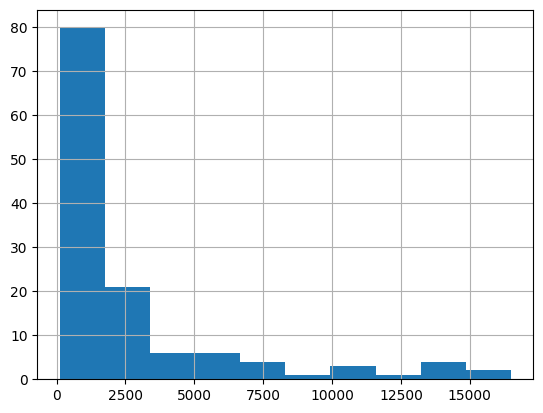

In [20]:
# B. Calculate B_ij (Budget / Tokens)
print("Calculating B_ij (Token Budget)...")
input_df['B_ij'] = input_df.progress_apply(calculate_b_ij_tokenized, axis=1)
input_df.B_ij.hist()

100%|██████████| 128/128 [00:00<00:00, 63580.16it/s]


<Axes: >

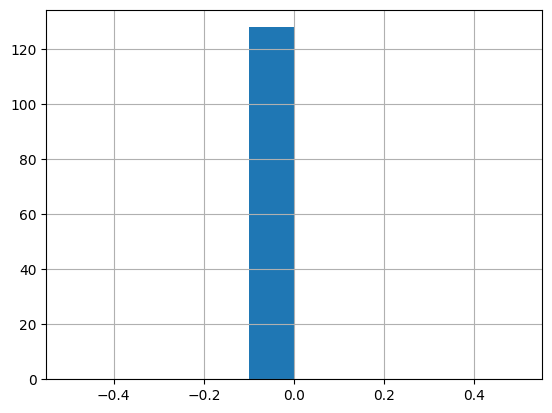

In [21]:
input_df['c_i'] = input_df.progress_apply(calculate_c_i_rigorous, axis=1)
input_df.c_i.hist()

In [22]:
input_df.subtask.value_counts()

subtask
LCB_generation       78
coding_completion    50
Name: count, dtype: int64

In [23]:
import ast
def structurize_json_coding(ss):
    # For LiveBench's coding
    try:
        if type(ss) == float:
            return ""
        
        if ss:
            ss = re.sub(r"(datetime\.datetime\([^)]+\))", r"'\1'", ss) # convert the datetime call into a simple string before parsing.
            return ast.literal_eval(ss)
        else:
            return {"None":"None"}
    except Exception as e:
        print(f"structurize_json_coding error : {e}")
        return None

if 'original_json' in input_df.columns: # INPUT_FILE_TYPE=='csv': # jsonl also needs to clean
    print('cleaning original_json...')
    input_df['original_json'] = input_df['original_json'].progress_apply(structurize_json_coding)

cleaning original_json...


100%|██████████| 128/128 [00:00<00:00, 11341.70it/s]


In [24]:
def structurize_partial_solution(ss):
    # For LiveBench's coding
    if type(ss) == float:
        return ""
    return ss

if 'partial_solution' in input_df.columns: # in our test only 'csv' is needed to be clean, but nothing is lost to safe-guard jsonl too
    print('cleaning partial_solution...')
    input_df['partial_solution'] = input_df['partial_solution'].progress_apply(structurize_partial_solution)

cleaning partial_solution...


100%|██████████| 128/128 [00:00<00:00, 199062.26it/s]


In [25]:
## check for empyty output before calculating score (KRI)
len_list = [len(input_df.iloc[i]['choices'][0]['turns'][-1]) for i in range(len(input_df))]
len_np = np.array(len_list)

min_idx = np.where(len_np == len_np.min())[0][0]
print(input_df.iloc[min_idx]['choices'][0]['turns'][-1]) # print content here

print(len_np.mean(), len_np.min(), len_np.max(), (len_np==0).sum()) # this is #chars,not #tokens

<think>
We just need simple compare. Output "Bat" if B > G else "Glove". Input format: two ints separated by space. We'll read sys.stdin. Implement solve().

Edge: ensure correct. We'll add main guard.

Return only code within triple backticks.
</think>
```python
import sys

def solve() -> None:
    data = sys.stdin.read().strip().split()
    if not data:
        return
    B, G = map(int, data)
    print("Bat" if B > G else "Glove")

if __name__ == "__main__":
    solve()
```
10107.4609375 481 64870 0


# Scoring Y_ij

In [26]:
%%time
input_df['Y_ij'] = input_df.progress_apply(safe_calculate_y_ij, axis=1)

  0%|          | 0/128 [00:00<?, ?it/s]

Evaluating 1...



  0%|          | 0/1 [00:00<?, ?it/s]

timeout occured: alarm went off



  2%|▏         | 2/128 [00:06<06:30,  3.10s/it]

Evaluating 1...


... (258 outputs left out)


100%|██████████| 128/128 [01:56<00:00,  1.03it/s]

Evaluating 1...



100%|██████████| 128/128 [01:56<00:00,  1.10it/s]

CPU times: user 10.9 s, sys: 5.59 s, total: 16.5 s
Wall time: 1min 56s


Y_ij
1.0    76
0.0    52
Name: count, dtype: int64

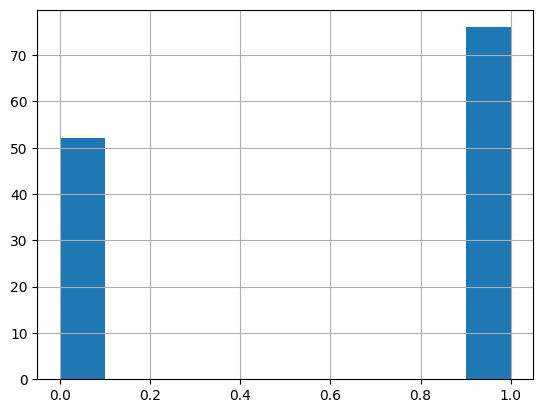

In [27]:
input_df['Y_ij'].hist()
input_df['Y_ij'].value_counts()

In [28]:
# Create a copy of the column on the fly using .assign()
input_df.assign(Y_val=input_df['Y_ij']).pivot_table(
    index='task', 
    columns='Y_ij', 
    values='Y_val', 
    aggfunc='count'
)

Y_ij,0.0,1.0
task,,
LCB_generation,24,54
coding_completion,28,22


In [29]:
from reasoning_aware_irt.livebench_utils import create_presence_table

Y_ij = create_presence_table(input_df, index_str='question_id', col_str='model_id', val_str='Y_ij', aggfunc='max')
B_ij = create_presence_table(input_df, index_str='question_id', col_str='model_id', val_str='B_ij', aggfunc='max')

# create c_i
C_series = input_df.groupby('question_id')['c_i'].first()
C_vector = C_series.reindex(Y_ij.index).fillna(0.0)



In [30]:
# delete github files 
!rm -rf /kaggle/working/reasoning-aware-irt
!rm -rf .* * 2>&- # Delete all LiveBench legacies

# TODO
# - ensure AMPS_hard is scored correctly

In [31]:
Y_ij.to_csv("matrix_Y.csv")
B_ij.to_csv("matrix_B.csv")
C_vector.to_csv("vector_c.csv")

print(Y_ij.shape, B_ij.shape, C_vector.shape)
Y_ij.head(3)

(128, 1) (128, 1) (128,)


model_id,openai/gpt-oss-20b
question_id,
009f4f7e8275c73de2eae601d76ff7163f613880788d870c1484b1c2a1383fbd,0.0
0119bdbf9e79f05e988b6d3408e2fdc0b7e4bc11e81ff9f24bed96268c503801,1.0
01c73e7f5bd7b486915f97829994aca9b95d6116c510d9f3781b5399dea066bd,1.0


In [32]:
!ls -sh

total 36K
12K matrix_B.csv  12K matrix_Y.csv  12K vector_c.csv


# EDA ScratchPad Zone

In [ ]:
Y_ij.values.sum()

76.0